# Employee Turnover Analytics
### _Machine Learning Portfolio Project_

### Understand the Problem

**Problem**

Employee turnover creates organizational costs through lost experience, recruitment, onboarding, and disruption to teams. The analytical problem is to determine whether employee data can be used to identify patterns associated with turnover and to estimate which employees are at greater risk of leaving.

**Goals**

- Explore employee data to identify meaningful patterns associated with turnover.
- Develop and compare machine-learning models for predicting employee attrition.
- Prioritize recall when selecting the final model so that employees at risk of leaving are less likely to be missed.
- Interpret the factors contributing most strongly to model predictions.
- Translate predictive probabilities into an illustrative risk-stratification framework for decision support.

**Deliverables**

- Exploratory data analysis and visualization.
- Employee segmentation using clustering.
- Baseline and tuned classification models.
- Evaluation and comparison of model performance.
- Feature-importance analysis.
- Illustrative employee risk stratification.
- Saved model artifacts supporting reproducibility and future inference.

**Audience**

The primary audience is an HR or people-analytics team evaluating how predictive modeling could support employee-retention analysis. Model outputs are intended to support further review and decision-making rather than serve as automated employment decisions.

## 1. Library Imports

In [1]:
# Core System & Utilities
import os, sys, math, json, warnings
import joblib

# Numerical Computing & Data Handling
import numpy as np
import pandas as pd

# Visualization & Exploratory Analysis
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import missingno as msno

# Statistical Tools
from scipy import stats

# Modeling, Evaluation & Preprocessing (scikit-learn)
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    accuracy_score, precision_score, recall_score, f1_score
)

# Core Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Clustering & Dimensionality Reduction
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Class Imbalance Handling
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Display Options & Warning Controls
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3f}".format

- All core libraries for data handling, visualization, and modeling were imported.
- Environment ready for data validation, exploratory analysis, feature engineering, and model training.  Warnings are suppressed to streamline output.

## 2. Load Data

In [2]:
data = pd.read_csv("data/P1Dataset_HR_comma_sep.csv")
data.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.380,0.530,2,157,3,0,1,0,sales,low
1,0.800,0.860,5,262,6,0,1,0,sales,medium
2,0.110,0.880,7,272,4,0,1,0,sales,medium
3,0.720,0.870,5,223,5,0,1,0,sales,low
4,0.370,0.520,2,159,3,0,1,0,sales,low


## 3. Data Quality Checks

#### **Overview:** Before performing our analysis and modeling, we must verify the dataset’s integrity to check for structural soundness, missing values, duplicates, and overall data composition.

#### *3.1 Data Inspection*

In [3]:
# Basic schema & data hygiene checks
data.info()
print("\nShape:", data.shape)
print("\nMissing values per column:\n", data.isna().sum().sort_values(ascending=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB

Shape: (14999, 10)

Missing values per column:
 satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident        

- The HR dataset loaded successfully with 14,999 observations and 10 variables.
- No missing values were detected.
- Numeric, categorical, and binary data types are
correctly recognized.

In [4]:
# Summary statistics
display(data.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.000,NaN,NaN,NaN,0.613,0.249,0.090,0.440,0.640,0.820,1.000
last_evaluation,14999.000,NaN,NaN,NaN,0.716,0.171,0.360,0.560,0.720,0.870,1.000
number_project,14999.000,NaN,NaN,NaN,3.803,1.233,2.000,3.000,4.000,5.000,7.000
average_montly_hours,14999.000,NaN,NaN,NaN,201.050,49.943,96.000,156.000,200.000,245.000,310.000
time_spend_company,14999.000,NaN,NaN,NaN,3.498,1.460,2.000,3.000,3.000,4.000,10.000
Work_accident,14999.000,NaN,NaN,NaN,0.145,0.352,0.000,0.000,0.000,0.000,1.000
left,14999.000,NaN,NaN,NaN,0.238,0.426,0.000,0.000,0.000,0.000,1.000
promotion_last_5years,14999.000,NaN,NaN,NaN,0.021,0.144,0.000,0.000,0.000,0.000,1.000
sales,14999,10,sales,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,14999,3,low,7316,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### *Summary of Descriptive Statistics*

- **Overall Data Health:**  
  All continuous features show valid numerical ranges and realistic spreads, with all columns containing complete data. This indicates that the dataset is clean and suitable for direct modeling without requiring imputation.

- **Continuous (Numeric) Features:**  
  Key performance and workload variables — *satisfaction level*, *last evaluation*, *number of projects*, *average monthly hours*, and *tenure* — display natural variation across employees. Satisfaction and evaluation both fall within the expected 0–1 scoring scale, while monthly hours and tenure exhibit wide spreads that may help differentiate employees with distinct workload or performance profiles.

- **Binary Features:**  
  Variables such as *work accident*, *left*, and *promotion in the last 5 years* follow expected 0/1 patterns. Notably, promotions are extremely rare (≈2%), a factor that may carry predictive weight in understanding voluntary departures.

- **Categorical Features:**  
  Both **Department** (`sales`) and **salary level** show clear, interpretable distributions. Departments appear reasonably represented across categories, while salary levels skew toward the lower end. These variables will require encoding prior to modeling but present well-structured, informative signals for supervised learning.

- **Early Indicators of Turnover Dynamics:**  
  The overall turnover rate (~24% of employees leaving) establishes an imbalanced target variable. Combined with variation in satisfaction, workload, and compensation level, these descriptive patterns identify variables worth examining further in the subsequent analysis.


#### *3.2 Data Cleaning*

In [5]:
# Remove duplicate rows to ensure unbiased data distribution
display(sorted(data.columns.tolist()))

['Work_accident',
 'average_montly_hours',
 'last_evaluation',
 'left',
 'number_project',
 'promotion_last_5years',
 'salary',
 'sales',
 'satisfaction_level',
 'time_spend_company']

In [6]:
# Standardize schema 
rename_map = {
    'sales': 'Department',
    'average_montly_hours': 'avg_monthly_hours',  # fix typo & standardize
    'Work_accident': 'work_accident'
}
data = data.rename(columns={k: v for k, v in rename_map.items() if k in data.columns})

In [7]:
# Check sales and salary columns for unique categorical values
print("\nUnique values in 'sales' column:")
print(data['Department'].unique())
print("\nUnique values in 'salary' column:")
print(data['salary'].unique())

# Remove duplicates
data = data.drop_duplicates()
print("\nDuplicate rows:", data.duplicated().sum())


Unique values in 'sales' column:
['sales' 'accounting' 'hr' 'technical' 'support' 'management' 'IT'
 'product_mng' 'marketing' 'RandD']

Unique values in 'salary' column:
['low' 'medium' 'high']

Duplicate rows: 0


- Duplicate records (≈20%) were identified and removed to prevent biased aggregation and modeling.

- Columns were standardized to ensure consistent naming and readability throughout the workflow and align with project terminology:
    - `sales` → `Department`
    - `average_montly_hours` → `avg_monthly_hours`
    - `Work_accident` → `work_accident`

#### *3.3 Checking for Outliers*

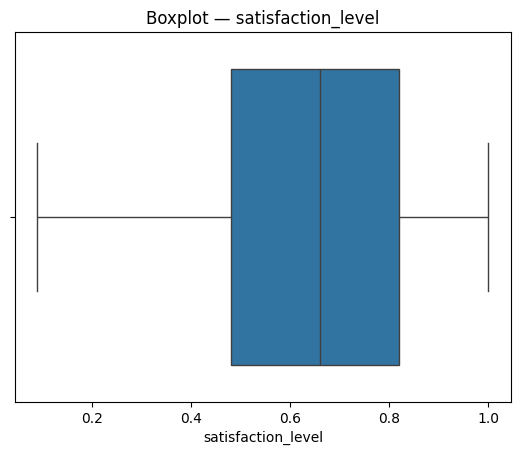

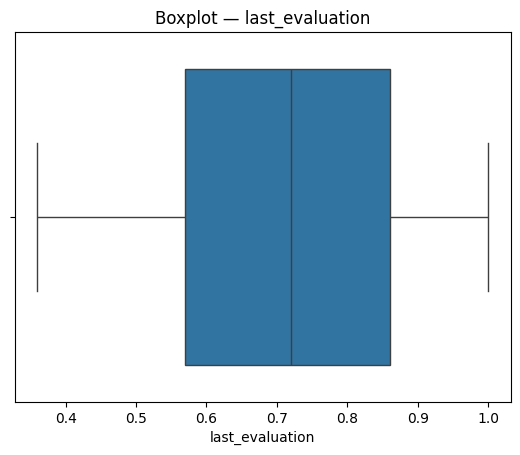

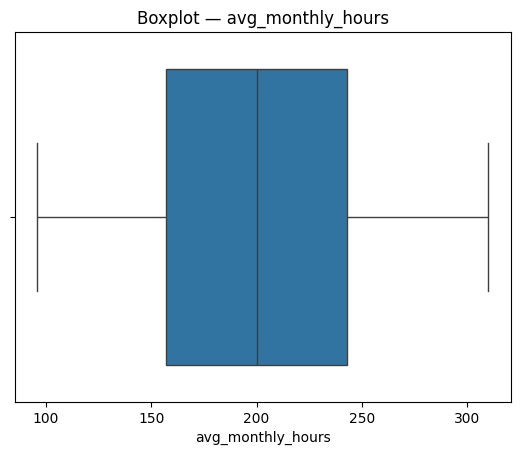

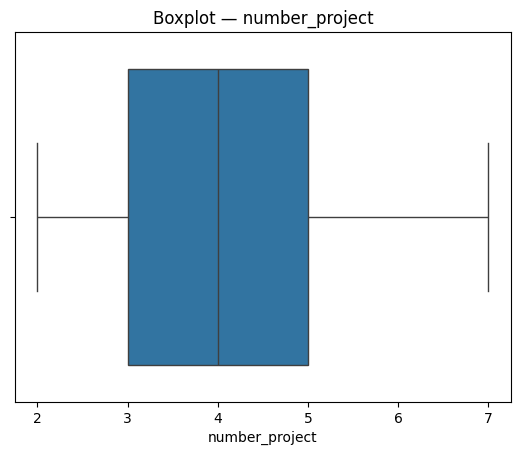

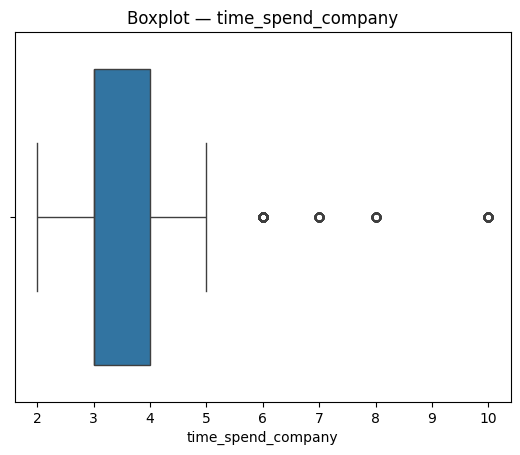

In [8]:
cont_cols = ['satisfaction_level', 'last_evaluation', 'avg_monthly_hours',
             'number_project', 'time_spend_company']  
for col in cont_cols:
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot — {col}')
    plt.show()

In [9]:
cont_cols = ['satisfaction_level', 'last_evaluation', 'avg_monthly_hours',
             'number_project', 'time_spend_company']

z = pd.DataFrame(stats.zscore(data[cont_cols], nan_policy='omit'),
                 columns=cont_cols)

# Counts per column
col_outliers = (np.abs(z) > 3).sum().sort_values(ascending=False)
print("Outliers > 3 SD by column:\n", col_outliers)

# Number of rows with any outlier in these columns
row_outliers = (np.abs(z) > 3).any(axis=1).sum()
print("Rows with any > 3 SD outlier:", row_outliers)

Outliers > 3 SD by column:
 time_spend_company    188
satisfaction_level      0
last_evaluation         0
avg_monthly_hours       0
number_project          0
dtype: int64
Rows with any > 3 SD outlier: 188


#### *Checking for Outliers Summary*

Boxplots were used to visually inspect the continuous variables for unusual or extreme values. Four of the five features (`satisfaction_level`, `last_evaluation`, `avg_monthly_hours`, and `number_project`) show no observations exceeding the statistical outlier threshold used below. The primary extreme values appear in **`time_spend_company`**, representing employees with longer tenure relative to the rest of the dataset.

To quantify these observations, z-scores were computed for each continuous feature. A z-score measures how far a data point lies from the mean in units of standard deviation. Using an absolute z-score greater than 3 as the threshold, **188 observations were identified as outliers, all in `time_spend_company`**. None of the other continuous features exceeded this threshold.

These observations were retained because they fall within the dataset's valid tenure range and were not identified as data errors. Removing them solely on the basis of statistical extremity could discard legitimate variation relevant to turnover prediction.

- Continuous features were reviewed through boxplots and z-score analysis.
- All 188 observations exceeding the ±3 standard-deviation threshold occurred in `time_spend_company`.
- Binary indicators were excluded from statistical outlier tests since such thresholds are not meaningful for dichotomous data.
- No records were removed at this stage because the identified values remained plausible within the dataset.
- Tree-based models used later are generally less sensitive to extreme values than linear models.

### **Summary:** The dataset is clean and validated for subsequent exploratory analysis. Structural, type, value-range, duplicate, and outlier checks have been completed, with legitimate extreme tenure observations retained for modeling.

## 4. Exploratory Data Analysis (EDA)

### **Overview:** This section examines relationships and distributions across the dataset to identify patterns that may influence employee turnover. Key variables are profiled both individually and in combination to establish context for model development.

#### *4.1 Correlation Matrix and Heatmap*
A correlation heatmap quantifies the linear relationships among numerical variables.
This will help identify features that move together, potential redundancy among predictors,
and early indications of which factors may be associated with turnover (`left`).

Interpretation focuses on the strength and direction of relationships between:
- Workload indicators (`avg_monthly_hours`, `number_project`)
- Tenure (`time_spend_company`)
- Employee engagement metrics (`satisfaction_level`, `last_evaluation`)
- Turnover flag (`left`)

Strong positive or negative correlations will inform both feature engineering and
subsequent modeling choices.

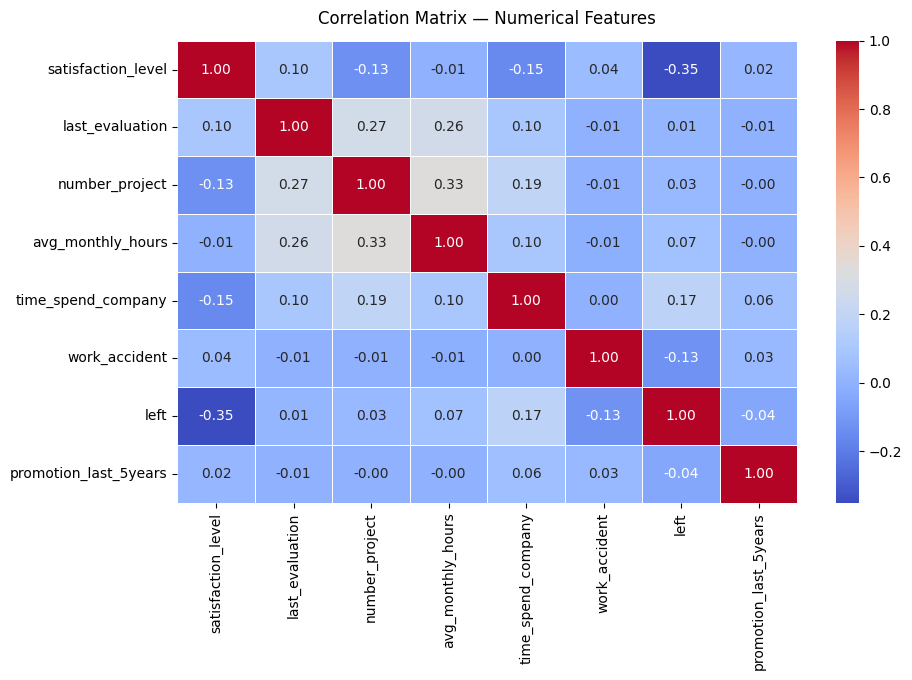

In [10]:
# Correlation matrix for numeric features
corr = data.select_dtypes(include=np.number).corr()

# Visualize correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix — Numerical Features', fontsize=12, pad=12)
plt.show()

#### *Correlation Matrix/Heatmap Summary*
- This correlation matrix summarizes linear relationships among numerical variables, including the
target (`left`).  The most notable pattern is a strong negative association between
**`satisfaction_level`** and turnover (r = –0.39), indicating that lower satisfaction strongly predicts
attrition.  

- Workload-related variables—`number_project`, `avg_monthly_hours`, and `last_evaluation`—
show moderate positive correlations with one another (r ≈ 0.3–0.4), suggesting they represent
a shared dimension of employee performance or intensity.  Their individual relationships with
turnover are weak, implying that workload effects may operate non-linearly or through interaction
with satisfaction.
    - Specifically, these three continuous variables represent the core behavioral dimensions most associated with voluntary turnover: satisfaction (engagement), last evaluation (performance/recognition), and average monthly hours (workload).
    
    - They offer clean, interpretable numeric distributions that strongly differentiate employees who stay from those who leave. While other variables are also relevant, these provide the most instructive and psychologically meaningful patterns for initial exploratory analysis.
 

- Other variables (tenure, accidents, promotions) exhibit minimal linear relationships with
turnover but remain relevant for interpretive completeness and later model testing.
Overall, these findings validate satisfaction as the primary turnover signal while
highlighting potential multicollinearity among workload measures.


#### *4.2 Distribution of Key Continuous Variables*

We are looking at the distribution of three key continuous variables:

- `satisfaction_level` — core engagement indicator
- `last_evaluation` — performance score
- `avg_monthly_hours` — workload measure

Together they provide an early quantitative picture of morale, performance, and work intensity — three factors critical to HR.

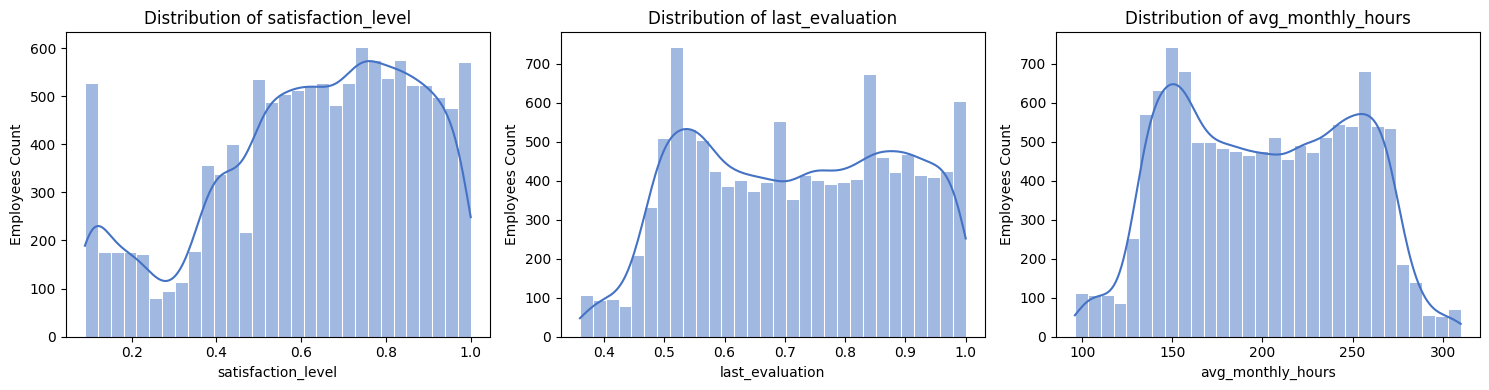

In [11]:
# Distribution plots for key continuous variables
features = ['satisfaction_level', 'last_evaluation', 'avg_monthly_hours']

plt.figure(figsize=(15, 4))
for i, col in enumerate(features, 1):
    plt.subplot(1, 3, i)
    sns.histplot(data[col], kde=True, bins=30, color='#4472C4', edgecolor='white')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Employees Count')
plt.tight_layout()
plt.show()

#### *Distribution Summary*
Distribution plots for `satisfaction level`, `last evaluation`, and `average monthly hours`
were generated to assess spread, central tendency, and potential skewness. Each blue bar represents the number of employees who left the company whose values for that variable fall within the given bin.

The visualizations reveal that:
- **Satisfaction** appears bimodal, separating lower- and higher-satisfaction groups within the workforce. More specifically:
    - The **first spike near 0** indicates a large group of employees with *very low satisfaction* who left the company.
    - The **dip** between about 0.15–0.38 shows relatively *few employees* in that middle-low satisfaction range.
    - The **rise again** from ~0.4 upward shows a second concentration of employees—those who left despite being moderately to highly satisfied.

        Together, these two peaks form a **bimodal distribution**—one cluster of unhappy employees (low satisfaction) and another of apparently satisfied but still departing employees.  

        This pattern is important because it hints that *attrition is not explained by dissatisfaction alone*; some high-performing, engaged employees may also be leaving, perhaps due to overwork, lack of advancement, or other organizational factors.


- **Evaluation scores** cluster near the upper range, reflecting generally strong performance appraisals. Notably, employee turnover is lowest among low-performing employees and highest among those with average to high evaluations, suggesting that attrition may be driven more by disengagement or overwork among competent staff than by poor performance.

- **Monthly working hours** The distribution of `avg_monthly_hours` among employees who left is **bimodal** with mild skew and long tails. 
    - One cluster of leavers worked **relatively fewer hours**, another worked **well above the norm**, with the largest group clustered around typical full-time workloads (~160–200 hours/month, or ~40–50 hours/week).  

    - This pattern suggests that **hours alone do not strongly predict attrition**.  

    - Instead, extreme workloads — either low (possible disengagement) or high (possible burnout) — may elevate turnover risk *in interaction with other factors*, such as satisfaction, number of projects, or tenure.

These patterns suggest distinct behavioral segments that may influence turnover: disengaged employees (low satisfaction) and over-extended high performers (high hours and evaluations).

The findings reinforce satisfaction as a key risk indicator and point to workload management as a potential intervention area; they also suggest that other variables may become risk factors when combined, a suggestion which warrants further investigation. 

#### *4.3 Project Count by Turnover Status*

The number of projects can reflect workload balance, role diversity, or potential burnout risk.

By comparing project counts between employees who stayed and those who left, we can:
- Identify whether turnover is concentrated among under-utilized or over-loaded employees.
- Detect non-linear risk patterns — e.g., higher attrition among both very low and very high project counts.
- Cross-check consistency with the earlier correlations (which suggested weak but non-zero links).

This visualization relates a categorical-count variable (`number_project`) directly to the target (`left`).

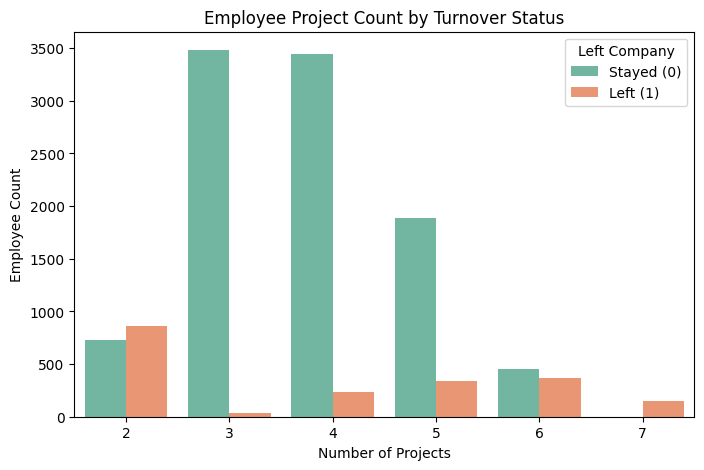

<Figure size 640x480 with 0 Axes>

In [12]:
# Bar plot of project count by turnover status
plt.figure(figsize=(8,5))
sns.countplot(x='number_project', hue='left', data=data, palette='Set2')
plt.title('Employee Project Count by Turnover Status')
plt.xlabel('Number of Projects')
plt.ylabel('Employee Count')
plt.legend(title='Left Company', labels=['Stayed (0)', 'Left (1)'])
plt.show()
plt.tight_layout()

Turnover rises at both tails of project count (≤2 and ≥6), consistent with under- and over-engagement.

#### *Distribution Summary*

- A grouped bar chart was created to compare the number of projects managed by employees
who remained versus those who left the organization.

- Results show the highest retention among employees with **moderate workloads** (approximately three projects).  Attrition increases at both extremes—employees with **very few projects** (possible disengagement) and those with **many projects** (potential overload). Of particular note:
    - In the `number_project` chart, employees with the **highest project counts** (typically 6 or 7 projects) are represented *only* among those who left — there are no bars for stayers in those bins.

    - Thus, number of projects shows a clear upper-limit effect — once employees exceed a manageable workload, retention collapses entirely.


These findings align with the workload correlations observed earlier and suggest
that turnover risk may follow a non-linear pattern: insufficient challenge and
excessive demand both elevate the likelihood of departure.

### *EDA Preliminary Insights Summary*

The exploratory analysis provides a clear empirical profile of the workforce and early signals of
the factors associated with employee turnover.

**Key Findings:**

- **Employee Satisfaction** emerged as the dominant linear indicator of turnover  
  (r = –0.39).  Low satisfaction strongly aligns with attrition, confirming its central role
  as a retention metric.

- **Workload and Performance Dynamics** show moderate inter-correlation among  
  `number_project`, `avg_monthly_hours`, and `last_evaluation` (r ≈ 0.3–0.4).  
  
  These variables describe a shared dimension of work intensity: employees who take on more projects tend to work longer hours and receive higher evaluations.

- **Non-linear Risk Patterns** are evident in the project-count analysis.  
  - Turnover is elevated at both extremes—among under-engaged employees with very few projects and among those handling excessive workloads.  
  
  - This suggests that attrition risk rises when either challenge or capacity balance is lost.

- **Tenure, Promotion, and Accident History** exhibit weak linear relationships with turnover, indicating that structural or policy factors play a secondary role compared with day-to-day engagement and workload experience.

**Implications:**

These findings reinforce satisfaction as the primary behavioral signal for predicting turnover
and highlight workload balance as a complementary management lever.

Subsequent modeling will test these relationships quantitatively—first through
clustering of employees who left, then through supervised classification models to predict
turnover probability across the organization.

## 5. Clustering — Behavioral Segmentation (K-Means on Leavers)

The exploratory analysis established satisfaction and workload as central behavioral dimensions
linked to turnover.  To further characterize employee segments within the departing population,
the next phase applies **unsupervised learning** through K-Means clustering.

This stage focuses exclusively on employees who left the company (`left = 1`) and examines
patterns across their **satisfaction level** and **last evaluation** scores.

The objective here is to identify natural groupings—such as low-satisfaction/low-evaluation employees
versus high-evaluation/high-workload leavers—and to interpret these segments in business terms.

Subsequent steps will:
1. Subset the dataset to employees who left.  
2. Perform feature scaling and K-Means clustering on `satisfaction_level` and `last_evaluation`.  
3. Visualize cluster membership and provide managerial interpretation of each group.


#### *5.1 Data Subset and Preparation*
- The clustering analysis isolates employees who left (`left = 1`) and focuses on their
`satisfaction_level` and `last_evaluation` scores.  
- These two continuous variables represent affective engagement and performance appraisal—the
behavioral dimensions most relevant to turnover segmentation.  
- Feature scaling is applied to ensure both variables contribute equally to the
distance metric used in K-Means.

In [13]:
# Subset to employees who left and select clustering features
feat_cols = ['satisfaction_level', 'last_evaluation']
left_emp = data.loc[data['left'] == 1, feat_cols].copy().reset_index(drop=True)

# Feature scaling
scaler = StandardScaler()
left_scaled = scaler.fit_transform(left_emp)

# Wrap into a DataFrame for quick inspection
left_scaled_df = pd.DataFrame(left_scaled, columns=feat_cols)

print("Scaled feature ranges (min/max):")
print(left_scaled_df.agg(['min', 'max']).round(3))

print("\nScaled feature center & spread (mean/std):")
print(pd.DataFrame({
    'mean': left_scaled_df.mean().round(3),
    'std' : left_scaled_df.std(ddof=0).round(3)  # population std for clarity
}))

# Preview scaled data
pd.DataFrame(left_scaled, columns=left_emp.columns).head(3)

Scaled feature ranges (min/max):
     satisfaction_level  last_evaluation
min              -1.321           -1.377
max               1.809            1.410

Scaled feature center & spread (mean/std):
                     mean   std
satisfaction_level -0.000 1.000
last_evaluation    -0.000 1.000


,satisfaction_level,last_evaluation
0,-0.227,-0.972
1,1.357,0.700
2,-1.246,0.802


#### *Feature Standardization as a Preliminary to Clustering*

We are clustering in this section to show how satisfaction and employee evaluation correlate and converge; to do that effectively, we scaled in order to put both variables on the same measurement scheme.

- Before clustering, numerical features must be expressed on a comparable scale so that distance-based algorithms interpret them correctly.  

- Here, `satisfaction_level` and `last_evaluation` are standardized (mean = 0, SD = 1) using `StandardScaler`, ensuring both contribute equally to distance calculations.

- The upcoming clustering step uses these standardized values to identify natural groupings among employees who left. 

- Each cluster represents employees with similar combinations of satisfaction and evaluation levels—revealing possible behavioral or motivational subgroups (e.g., dissatisfied low performers vs. highly evaluated but disengaged staff).

#### *5.2 K-Means Clustering*

- K-Means clustering partitions the departing employees into groups based on similar satisfaction and evaluation profiles.

- The model is initialized with **three clusters** for this analysis.

- `random_state = 42` ensures reproducibility.

In [14]:
kmeans = KMeans(n_clusters=3, random_state=42)
cluster_labels = kmeans.fit_predict(left_scaled)

# Attach labels back to a working frame
left_emp_clusters = left_emp.copy()
left_emp_clusters['cluster'] = cluster_labels

# Cluster sizes
print("Cluster counts:")
print(left_emp_clusters['cluster'].value_counts().sort_index())
print()

# Centroids in scaled units
centroids_scaled = kmeans.cluster_centers_
print("Cluster centers (scaled units):")
print(pd.DataFrame(centroids_scaled, columns=feat_cols).round(3))
print()

# --- Centroids back-transformed to original feature units (HR-friendly) ---
centroids_original = scaler.inverse_transform(centroids_scaled)
print("Cluster centers (original units):")
print(pd.DataFrame(centroids_original, columns=feat_cols).round(3))
print()

# Optional transparency: within-cluster SSE (inertia)
print("K-Means inertia (within-cluster SSE):", round(kmeans.inertia_, 2))

Cluster counts:
cluster
0    907
1    553
2    531
Name: count, dtype: int64

Cluster centers (scaled units):
   satisfaction_level  last_evaluation
0              -0.110           -1.040
1               1.371            0.980
2              -1.240            0.756

Cluster centers (original units):
   satisfaction_level  last_evaluation
0               0.411            0.516
1               0.804            0.915
2               0.112            0.871

K-Means inertia (within-cluster SSE): 299.07


#### *5.3 Cluster Visualization*
Cluster membership is visualized in satisfaction–evaluation space to reveal the
behavioral profiles of employees who left.  
The plot highlights potential patterns such as:
- **Low satisfaction / low evaluation** → disengaged performers.  
- **High satisfaction / high evaluation** → high achievers leaving voluntarily.  
- **Moderate satisfaction / high evaluation** → possibly over-extended staff.

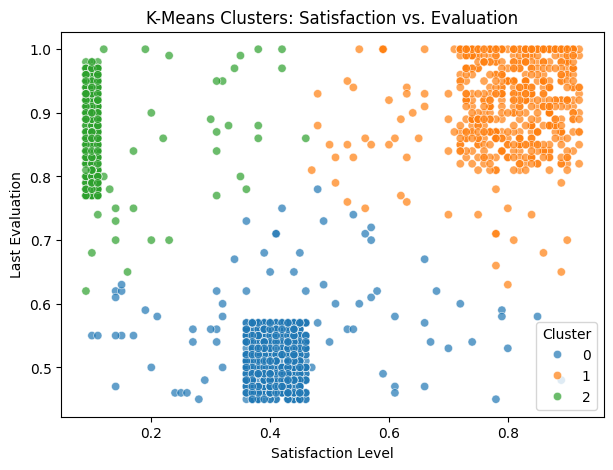

In [15]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=left_emp_clusters,
    x='satisfaction_level', y='last_evaluation',
    hue='cluster', palette='tab10', alpha=0.7
)
plt.title('K-Means Clusters: Satisfaction vs. Evaluation')
plt.xlabel('Satisfaction Level')
plt.ylabel('Last Evaluation')
plt.legend(title='Cluster')
plt.show()

Clusters segment as (C0) low-satisfaction/low-evaluation, (C1) high-satisfaction/high-evaluation, (C2) medium-evaluation/low-satisfaction.

#### *5.4 Cluster Interpretation and Insights*

Three distinct profiles emerge among employees who left:

1. **Cluster 0 — Low Satisfaction / Low Evaluation**  
   Characterized by relatively low satisfaction and lower evaluation scores.

2. **Cluster 1 — High Satisfaction / High Evaluation**  
   Characterized by relatively high satisfaction and higher evaluation scores.

3. **Cluster 2 — Low Satisfaction / Moderate Evaluation**  
   Characterized by relatively low satisfaction alongside moderate evaluation scores.

These clusters provide a descriptive framework for examining heterogeneity among employees who left the organization. They show that departing employees do not share a single satisfaction/evaluation profile, which may be useful for subsequent analysis of turnover patterns.

Because the clustering uses satisfaction and evaluation measures rather than information about employees' reasons for leaving, the clusters should not by themselves be interpreted as identifying particular causes or types of turnover.

## 6. Preprocessing — Encoding & Train/Test Split
- This section converts categorical variables into numeric form, combines them with numeric features, and performs a stratified train/test split.
- The goal is to prepare balanced, model-ready data while preserving the original feature semantics.

#### *6.1 Feature Encoding and Dataset Assembly*
Categorical variables (`Department`, `salary`) must be numerically encoded so that models can
interpret them.  One-hot encoding is applied via `pd.get_dummies()`, producing binary indicator
columns while avoiding the dummy-variable trap by dropping one reference category per feature.
Numeric variables are retained in their original form and combined with the encoded features
to create the final feature matrix.

In [16]:
# Separate feature groups
cat_cols = ['Department', 'salary']
num_cols = [
    'satisfaction_level', 'last_evaluation', 'number_project',
    'avg_monthly_hours', 'time_spend_company',
    'work_accident', 'promotion_last_5years'
]

# One-hot encode categorical variables (drop_first=True avoids redundancy)
encoded = pd.get_dummies(data[cat_cols], drop_first=True)

# Combine numeric and encoded features
X = pd.concat([data[num_cols], encoded], axis=1)
y = data['left']

print("Feature matrix shape:", X.shape)
print("\nTarget variable distribution:", y.value_counts(normalize=True))

# Check that encoding transformed all values to numeric (optional, but a clear display that the encoding worked)
print("\nRemaining object columns:", X.select_dtypes('object').columns.tolist())

Feature matrix shape: (11991, 18)

Target variable distribution: left
0   0.834
1   0.166
Name: proportion, dtype: float64

Remaining object columns: []


#### *6.2 Train/Test Split (Stratified)*
- To ensure class proportions remain consistent across training and testing datasets,
a stratified 80/20 split is performed.  
- `random_state=123` guarantees reproducibility.  
- The resulting subsets serve as inputs for later oversampling (training only) and model evaluation.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=123
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("\nTraining target distribution:", y_train.value_counts(normalize=True))

print("\nTrain class ratio:", round(y_train.mean(),3))
print("Test  class ratio:", round(y_test.mean(),3))

Training set shape: (9592, 18)
Test set shape: (2399, 18)

Training target distribution: left
0   0.834
1   0.166
Name: proportion, dtype: float64

Train class ratio: 0.166
Test  class ratio: 0.166


#### *Preprocessing Summary*
The preprocessing phase produced a fully numeric, model-ready dataset with all variables
correctly encoded and class proportions preserved across training and testing subsets.

Key outcomes:
- **Categorical encoding** completed for `Department` and `salary`.  
- **Feature matrix (X)** and **target vector (y)** established.  
- **Stratified 80/20 split** ensures consistent turnover representation in both subsets.

The next section addresses class imbalance in the training data using the SMOTE technique.

## 7. Class Imbalance — SMOTE (Train Only)
Turnover is relatively infrequent compared with retention, producing a class imbalance that can bias model training toward the majority class. To counteract this, we apply **Synthetic Minority Oversampling Technique (SMOTE)** to the **training set only**, generating synthetic minority samples to balance the class distribution. The test set remains untouched for unbiased evaluation.

#### *7.1 Class Balance Check (Pre-SMOTE)*
We first quantify the class distribution in the training split to confirm the extent of imbalance.

In [18]:
# Pre-SMOTE class ratio
print("Training target distribution (pre-SMOTE):")
print(y_train.value_counts(normalize=True).rename({0:'Stayed', 1:'Left'}).round(3))

# Optional: quick counts
print("\nCounts (pre-SMOTE):")
print(y_train.value_counts().rename({0:'Stayed', 1:'Left'}))

Training target distribution (pre-SMOTE):
left
Stayed   0.834
Left     0.166
Name: proportion, dtype: float64

Counts (pre-SMOTE):
left
Stayed    7999
Left      1593
Name: count, dtype: int64


#### *7.2 SMOTE Oversampling (Train Only)*
SMOTE is applied to the training features and labels to synthetically oversample the minority class.
The operation is restricted to the training set to avoid data leakage. A fixed `random_state`
ensures reproducible results.

Resampled training shapes: (15998, 18) (15998,)

Counts (post-SMOTE):
left
Stayed    7999
Left      7999
Name: count, dtype: int64

Training target distribution (post-SMOTE):
left
Stayed   0.500
Left     0.500
Name: proportion, dtype: float64


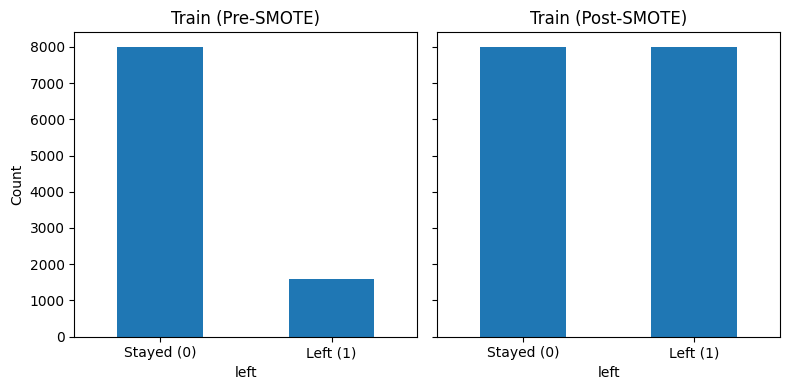

In [19]:
smote = SMOTE(random_state=123, k_neighbors=5)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Resampled training shapes:", X_train_res.shape, y_train_res.shape)

print("\nCounts (post-SMOTE):")
print(y_train_res.value_counts().rename({0:'Stayed', 1:'Left'}))

print("\nTraining target distribution (post-SMOTE):")
print(y_train_res.value_counts(normalize=True).rename({0:'Stayed', 1:'Left'}).round(3))

# Optional quick bar chart of class balance pre/post for a visual confirmation of class balances after SMOTE
fig, ax = plt.subplots(1, 2, figsize=(8,4), sharey=True)
y_train.value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Train (Pre-SMOTE)')
y_train_res.value_counts().sort_index().plot(kind='bar', ax=ax[1], title='Train (Post-SMOTE)')
for a in ax:
    a.set_xticklabels(['Stayed (0)','Left (1)'], rotation=0)
    a.set_ylabel('Count')
plt.tight_layout()
plt.show()

#### *7.3 QA Check on Test Data*
This quick check ensures that only the training set was resampled and the test set remains unchanged.

In [20]:
# Guard against accidental resampling of the test set
assert X_test.shape[0] == y_test.shape[0], "Test X/y mismatch."
# Confirm original test class ratio was preserved (optional)
print("Test target distribution (unchanged):")
print(y_test.value_counts(normalize=True).rename({0:'Stayed', 1:'Left'}).round(3))

Test target distribution (unchanged):
left
Stayed   0.834
Left     0.166
Name: proportion, dtype: float64


### *Class Balance Summary*

- The training data exhibited a pronounced class imbalance, with approximately **16.6%** of employees having left the organization.

- To mitigate potential model bias toward the majority (retention) class, the **Synthetic Minority Oversampling Technique (SMOTE)** was applied to the training data.

- SMOTE synthetically generated minority-class examples until the training classes were balanced, providing subsequent models with greater representation of employees who left.

- The test set remained untouched, preserving the original **16.6%** attrition rate and providing an evaluation set that reflects the original class distribution.

- Post-SMOTE diagnostics confirm equal class representation in the resampled training data and unchanged class proportions in the test data.

- In subsequent model evaluation and tuning, SMOTE is incorporated within the modeling pipeline so that resampling occurs only on training data and does not introduce information from the held-out test set.

## 8. Baseline Model Evaluation

With the dataset fully preprocessed and class imbalance addressed, this section develops and evaluates baseline classification models to predict employee turnover.

Three algorithms are compared:

1. Logistic Regression  
2. Random Forest Classifier  
3. Gradient Boosting Classifier

Each baseline model is trained on the training data and evaluated on the held-out test set. SMOTE is incorporated within each modeling pipeline to address class imbalance during training.

Performance is assessed using accuracy, recall, precision, F1-score, ROC-AUC, and confusion matrices.

##### *Model Evaluation Metrics*

| Metric | Definition | Measures | Use in this Project |
|---------|-------------|-----------|---------------------|
| **Accuracy** | (TP+TN)/(TP+TN+FP+FN) | Overall correctness | Misleading under imbalance; baseline indicator only. |
| **Recall** | TP/(TP+FN) | % of actual leavers correctly identified | Key for detecting at-risk employees. |
| **Precision** | TP/(TP+FP) | % of predicted leavers who truly left | Ensures credibility; avoids false alarms. |
| **F1-Score** | 2 × (Prec×Rec)/(Prec+Rec) | Balance of precision and recall | Single, balanced performance metric. |
| **ROC/AUC** | ROC = curve of TPR vs. FPR; AUC = area under it | Overall separability of classes | Higher AUC = stronger distinction between leavers and stayers. |

The **confusion matrix** summarizes prediction outcomes by showing the counts of true positives, true negatives, false positives, and false negatives and provides a quick visual check of where the model is performing well and where it is misclassifying—especially useful here for assessing imbalance between leavers and stayers.


#### *8.1 Define Cross-Validation Strategy*

A stratified 5-fold cross-validation strategy is defined for subsequent model tuning. Stratification preserves the relative representation of leavers and stayers within each fold, while the fixed `random_state` supports reproducibility.

The `cv` object establishes a reusable cross-validation configuration for later model-selection and tuning procedures.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

A stratified 5-fold cross-validation strategy is defined for subsequent model tuning. Stratification preserves the relative representation of leavers and stayers within each fold, while the fixed `random_state` supports reproducibility.

The `cv` object establishes a reusable cross-validation configuration for later model-selection and tuning procedures.

#### *8.2 Logistic Regression (Baseline Linear Model)*

Logistic Regression serves as a baseline for evaluating a linear decision boundary in the turnover data. SMOTE is integrated into the pipeline to rebalance the training data before model fitting.

Classification Report — Logistic Regression:

              precision    recall  f1-score   support

           0      0.924     0.822     0.870      2001
           1      0.425     0.661     0.517       398

    accuracy                          0.795      2399
   macro avg      0.675     0.741     0.694      2399
weighted avg      0.841     0.795     0.812      2399

ROC-AUC: 0.803


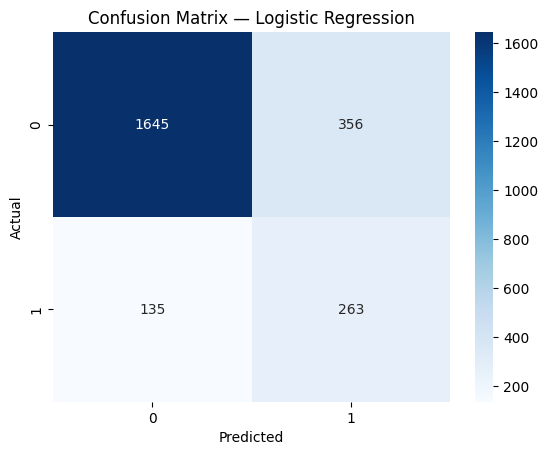

In [22]:
pipe_lr = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('model', LogisticRegression(max_iter=1000, random_state=123))
])

pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)
y_prob_lr = pipe_lr.predict_proba(X_test)[:, 1]

print("Classification Report — Logistic Regression:\n")
print(classification_report(y_test, y_pred_lr, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 3))

# Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### *8.3 Random Forest Classifier (Ensemble Model)*
The Random Forest model captures non-linear relationships and feature interactions using an ensemble of decision trees.

Classification Report — Random Forest:

              precision    recall  f1-score   support

           0      0.981     0.989     0.985      2001
           1      0.942     0.905     0.923       398

    accuracy                          0.975      2399
   macro avg      0.962     0.947     0.954      2399
weighted avg      0.975     0.975     0.975      2399

ROC-AUC: 0.976


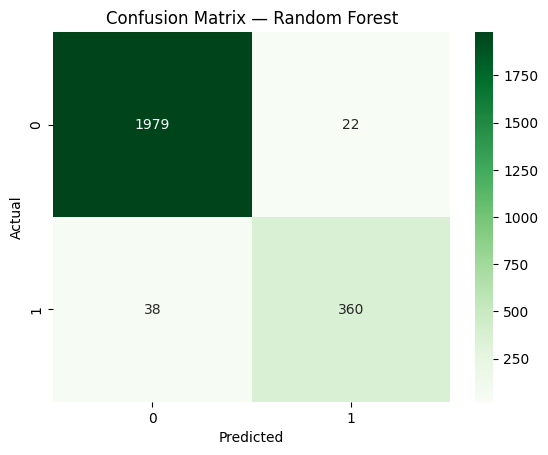

In [23]:
pipe_rf = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('model', RandomForestClassifier(
        n_estimators=200, random_state=123, n_jobs=-1))
])

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)
y_prob_rf = pipe_rf.predict_proba(X_test)[:, 1]

print("Classification Report — Random Forest:\n")
print(classification_report(y_test, y_pred_rf, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 3))

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix — Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### *8.4 Gradient Boosting Classifier (Ensemble Model)*

Gradient Boosting is a sequential ensemble method that builds a strong predictive model by iteratively adding trees that correct errors made by the existing ensemble.

It is evaluated here as a flexible non-linear model capable of capturing complex relationships in the turnover data.

Classification Report — Gradient Boosting:

              precision    recall  f1-score   support

           0      0.985     0.972     0.978      2001
           1      0.868     0.925     0.895       398

    accuracy                          0.964      2399
   macro avg      0.926     0.948     0.937      2399
weighted avg      0.965     0.964     0.965      2399

ROC-AUC: 0.98


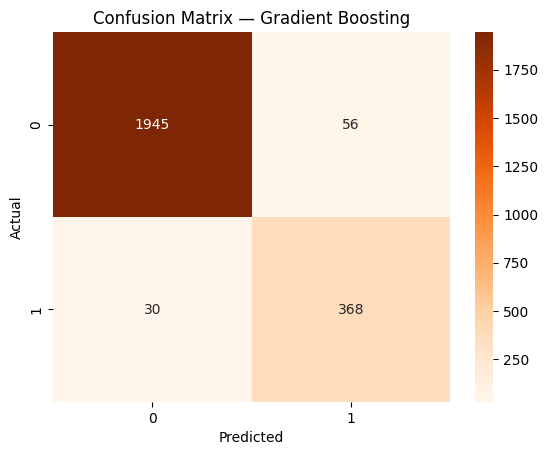

In [24]:
pipe_gb = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('model', GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.1, random_state=123))
])

pipe_gb.fit(X_train, y_train)
y_pred_gb = pipe_gb.predict(X_test)
y_prob_gb = pipe_gb.predict_proba(X_test)[:, 1]

print("Classification Report — Gradient Boosting:\n")
print(classification_report(y_test, y_pred_gb, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_gb), 3))

cm_gb = confusion_matrix(y_test, y_pred_gb)
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix — Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### *8.5 ROC Curve Comparison Across Models*

- A Receiver Operating Characteristic (ROC) curve compares true positive and false positive rates across different probability thresholds.

- Plotting all three models together allows direct comparison of their ability to distinguish between leavers and stayers across classification thresholds.

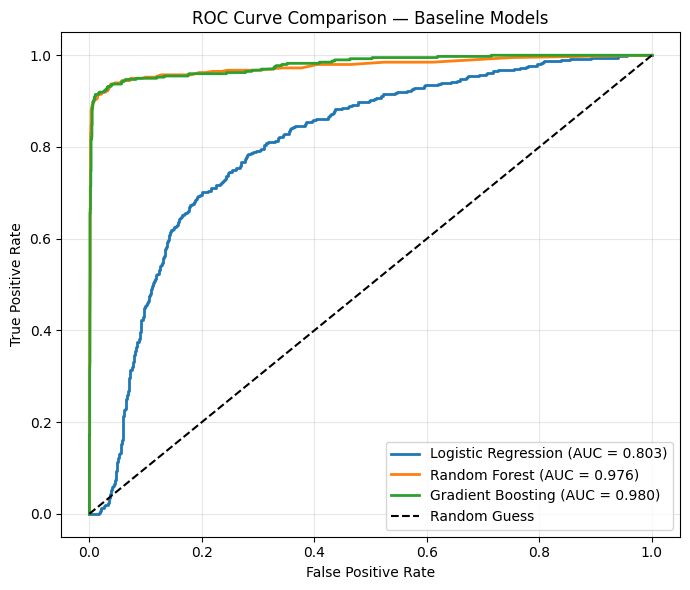

In [25]:
# ROC Curve comparison for all models
plt.figure(figsize=(7,6))

# Compute curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)

# Compute AUCs
auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)
auc_gb = auc(fpr_gb, tpr_gb)

# Plot curves
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', linewidth=2)
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_gb:.3f})', linewidth=2)

# Reference line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Formatting
plt.title('ROC Curve Comparison — Baseline Models', fontsize=12)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### *ROC Curve Comparison Summary*

- Both ensemble models show substantially stronger discrimination than Logistic Regression, with ROC-AUC values of **0.976 for Random Forest** and **0.980 for Gradient Boosting**, compared with **0.803 for Logistic Regression**.

- Gradient Boosting achieved the highest baseline ROC-AUC, although its performance was very close to that of Random Forest.

- The results suggest that the ensemble models capture predictive relationships in the turnover data that are not represented as effectively by the linear Logistic Regression baseline.

#### *8.6 Model Comparison Summary*

The three baseline models achieved the following performance on the held-out test set:

| Model | Precision | Recall | F1 | ROC-AUC |
|--------|-----------|--------|----|---------|
| Logistic Regression | 0.425 | 0.661 | 0.517 | 0.803 |
| Random Forest | 0.942 | 0.905 | 0.923 | 0.976 |
| Gradient Boosting | 0.868 | 0.925 | 0.895 | 0.980 |

- Both ensemble models substantially outperform Logistic Regression across the principal classification metrics.

- Random Forest achieves the highest precision and F1-score, while Gradient Boosting achieves the highest recall and ROC-AUC.

- Logistic Regression remains valuable as an interpretable linear baseline, providing a transparent point of comparison with the nonlinear ensemble models.

- Because recall is particularly important when the goal is to identify employees at risk of leaving, Gradient Boosting's higher baseline recall is relevant to subsequent model tuning and final model selection.

### *Baseline Model Evaluation Summary*

Three baseline models were trained on the training data with SMOTE incorporated into each modeling pipeline and evaluated on the held-out test set.

The ensemble methods (Random Forest and Gradient Boosting) substantially outperformed the Logistic Regression baseline, indicating that nonlinear models are better suited to the predictive patterns present in this dataset.

- **Logistic Regression** provides an interpretable linear benchmark.

- **Random Forest** captures nonlinear relationships and interactions among features and achieved the highest baseline precision and F1-score.

- **Gradient Boosting** provides a second ensemble approach and achieved the highest baseline recall and ROC-AUC.

Together, these baseline results establish a performance benchmark for subsequent model optimization. The stratified 5-fold cross-validation strategy defined earlier will be used during hyperparameter tuning to evaluate candidate model configurations more robustly.

The next step focuses on hyperparameter tuning and model selection, with particular attention to recall as an important metric for identifying employees at risk of leaving.

## 9. Hyperparameter Optimization (Recall-Focused)

- Baseline model results demonstrated that ensemble methods outperform the linear baseline.

- To improve sensitivity to potential leavers, we perform hyperparameter optimization using **GridSearchCV**. The primary scoring metric is **recall**, reflecting the objective of identifying as many true leavers as possible. Precision, F1, and ROC-AUC are also evaluated to assess the resulting trade-offs.

#### *9.1 Random Forest — Grid Search*

The Random Forest model is tuned across a moderate parameter grid covering the number of trees, tree depth, minimum samples required for splits and leaves, and feature sampling strategy. Recall is used as the primary scoring metric to prioritize detection of true leavers.

In [26]:
# Pipeline with SMOTE inside CV
pipe_rf = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('model', RandomForestClassifier(random_state=123))
])

# Parameter grid (moderate search range)
param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 8, 12, 16],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid_rf,
    scoring='recall',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("\nBest Parameters — Random Forest:")
print(grid_rf.best_params_)
print(f"Best Recall Score: {grid_rf.best_score_:.3f}")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits

Best Parameters — Random Forest:
{'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__min_samples_split': 10, 'model__n_estimators': 200}
Best Recall Score: 0.916


#### *9.2 Evaluate Tuned Random Forest on Test Data*

The tuned Random Forest model is evaluated on the hold-out test set to assess generalization performance and measure recall alongside precision, F1, and ROC-AUC.

Classification Report — Tuned Random Forest:

              precision    recall  f1-score   support

           0      0.981     0.985     0.983      2001
           1      0.921     0.905     0.913       398

    accuracy                          0.971      2399
   macro avg      0.951     0.945     0.948      2399
weighted avg      0.971     0.971     0.971      2399

ROC-AUC: 0.976


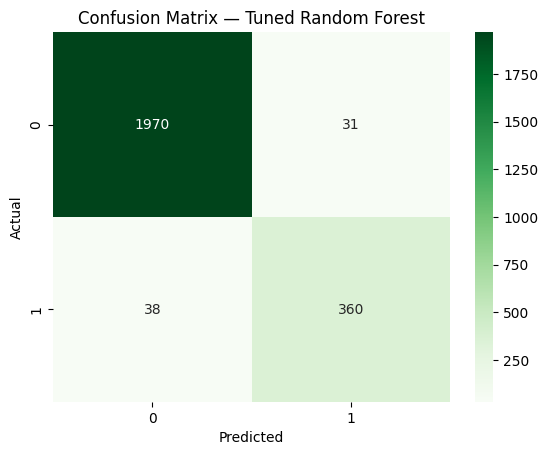

In [27]:
best_rf = grid_rf.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)[:,1]

print("Classification Report — Tuned Random Forest:\n")
print(classification_report(y_test, y_pred_rf_tuned, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf_tuned), 3))

cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)
sns.heatmap(cm_rf_tuned, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix — Tuned Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Tuned RF: recall = 0.905, precision = 0.921, F1 = 0.913, ROC-AUC = 0.976 (held-out test set).

#### *9.3 Gradient Boosting — Grid Search*

Gradient Boosting is tuned across learning rate, number of estimators, tree depth, and minimum samples required to split an internal node. Recall is again the primary optimization criterion.

In [28]:
pipe_gb = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('model', GradientBoostingClassifier(random_state=123))
])

param_grid_gb = {
    'model__n_estimators': [100, 150, 200],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__max_depth': [3, 4, 5],
    'model__min_samples_split': [2, 5, 10]
}

grid_gb = GridSearchCV(
    estimator=pipe_gb,
    param_grid=param_grid_gb,
    scoring='recall',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_gb.fit(X_train, y_train)

print("Best Parameters — Gradient Boosting:\n")
print(grid_gb.best_params_)
print(f"Best Recall Score: {grid_gb.best_score_:.3f}")


Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters — Gradient Boosting:

{'model__learning_rate': 0.2, 'model__max_depth': 4, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best Recall Score: 0.930


#### *9.4 Evaluate Tuned Gradient Boosting on Test Data*
The tuned Gradient Boosting model is assessed on the hold-out test set for recall, precision, F1-score, and ROC-AUC.

Classification Report — Tuned Gradient Boosting:

              precision    recall  f1-score   support

           0      0.984     0.982     0.983      2001
           1      0.910     0.920     0.915       398

    accuracy                          0.972      2399
   macro avg      0.947     0.951     0.949      2399
weighted avg      0.972     0.972     0.972      2399

ROC-AUC: 0.98


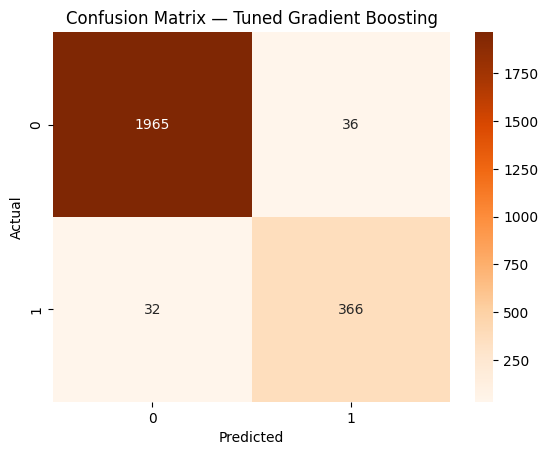

In [29]:
best_gb = grid_gb.best_estimator_

y_pred_gb_tuned = best_gb.predict(X_test)
y_prob_gb_tuned = best_gb.predict_proba(X_test)[:,1]

print("Classification Report — Tuned Gradient Boosting:\n")
print(classification_report(y_test, y_pred_gb_tuned, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_gb_tuned), 3))

cm_gb_tuned = confusion_matrix(y_test, y_pred_gb_tuned)
sns.heatmap(cm_gb_tuned, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix — Tuned Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Tuned GB: recall = 0.920, precision = 0.910, F1 = 0.915, ROC-AUC = 0.980 (held-out test set).

#### *9.5 Comparative Assessment of Random Forest and Gradient Boosting*

Both tuned ensemble models perform strongly on the hold-out test set, with different trade-offs between recall and precision.

In this project’s context—where identifying true leavers is prioritized—**Gradient Boosting** is selected as the preferred model for subsequent interpretation because it achieves the higher recall (0.920 vs. 0.905), while also producing slightly higher F1 and ROC-AUC. Random Forest achieves slightly higher precision.

In [30]:
results_summary = pd.DataFrame({
    'Model': ['Random Forest (Tuned)', 'Gradient Boosting (Tuned)'],
    'Recall': [
        recall_score(y_test, y_pred_rf_tuned),
        recall_score(y_test, y_pred_gb_tuned)
    ],
    'Precision': [
        precision_score(y_test, y_pred_rf_tuned),
        precision_score(y_test, y_pred_gb_tuned)
    ],
    'F1': [
        f1_score(y_test, y_pred_rf_tuned),
        f1_score(y_test, y_pred_gb_tuned)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_rf_tuned),
        roc_auc_score(y_test, y_prob_gb_tuned)
    ]
})
print(results_summary.round(3))

                       Model  Recall  Precision    F1  ROC-AUC
0      Random Forest (Tuned)   0.905      0.921 0.913    0.976
1  Gradient Boosting (Tuned)   0.920      0.910 0.915    0.980


### *Hyperparameter Optimization Summary*

Hyperparameter tuning was performed via 5-fold GridSearchCV, with recall used as the primary optimization criterion.

- The **Random Forest (tuned)** model achieved recall of **0.905**, precision of **0.921**, F1-score of **0.913**, and ROC-AUC of **0.976**.

- The **Gradient Boosting (tuned)** model achieved recall of **0.920**, precision of **0.910**, F1-score of **0.915**, and ROC-AUC of **0.980**.

Given the project’s emphasis on identifying true leavers, **Gradient Boosting** is selected for subsequent interpretation. It achieves the higher recall while also producing slightly higher F1 and ROC-AUC, although Random Forest retains a modest advantage in precision.

The next section examines feature importance within the tuned Gradient Boosting model to identify the features that contribute most strongly to its predictions.

## 10. Best Model Selection & Feature Importance

- After hyperparameter optimization, both ensemble models demonstrated strong performance on the hold-out test set.

- The **tuned Gradient Boosting model** achieved higher recall (0.920), F1-score (0.915), and ROC-AUC (0.980), while the tuned Random Forest achieved higher precision (0.921).

- Because recall was prioritized for identifying employees at risk of leaving, Gradient Boosting is selected as the final model for interpretation and decision-support analysis.

- The following section examines **feature importance** within the tuned Gradient Boosting model to identify the features that contribute most strongly to its predictions.

#### *10.1 Confirm Best Model and Save Reference*

The tuned Gradient Boosting model reflects the configuration selected via 5-fold GridSearchCV. It will serve as the final model for subsequent interpretation and decision-support analysis.

In [31]:
# Confirm best model object from GridSearch
best_model = grid_gb.best_estimator_
print(best_model)

Pipeline(steps=[('smote', SMOTE(random_state=123)),
                ('model',
                 GradientBoostingClassifier(learning_rate=0.2, max_depth=4,
                                            random_state=123))])


The selected Gradient Boosting model uses a learning rate of 0.2 and a maximum tree depth of 4, as determined through GridSearchCV. Other parameters retain their default values.

#### *10.2 Compute Feature Importance*

Gradient Boosting provides built-in feature importance values based on the contribution of each feature to reducing the model's splitting criterion across the ensemble. Higher values indicate greater importance to the model's predictions.

In [32]:
# Extract feature importances
importances = best_model.named_steps['model'].feature_importances_
features = X_train.columns

feat_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display top 15
feat_importance.head(15)

,Feature,Importance
0,satisfaction_level,0.433
4,time_spend_company,0.344
1,last_evaluation,0.090
3,avg_monthly_hours,0.072
2,number_project,0.030
17,salary_medium,0.009
5,work_accident,0.008
16,salary_low,0.004
14,Department_support,0.003
13,Department_sales,0.002


#### *10.3 Visualize Feature Importance*
A horizontal bar chart displays the relative importance of top-ranked predictors.

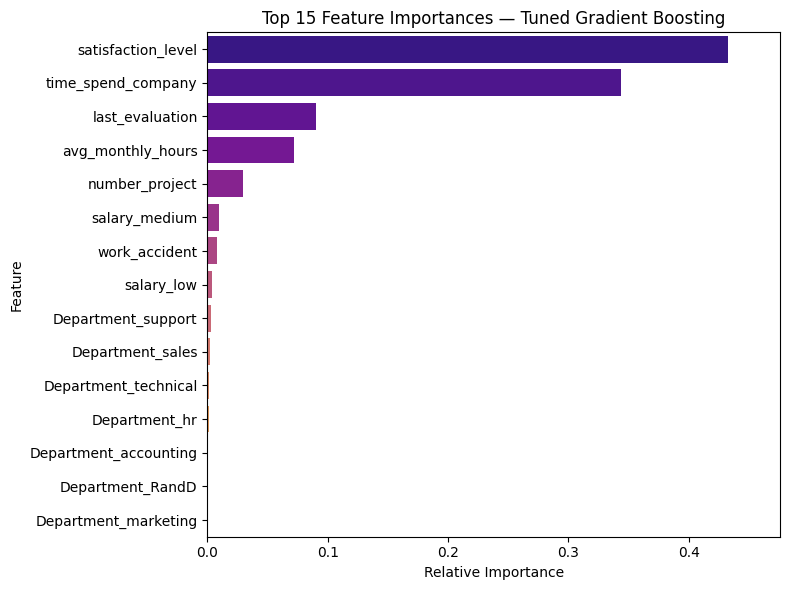

In [33]:
plt.figure(figsize=(8,6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feat_importance.head(15),
    palette='plasma'
)
plt.title('Top 15 Feature Importances — Tuned Gradient Boosting')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.xlim(0, feat_importance['Importance'].max()*1.1)
plt.tight_layout()
plt.show()

#### *10.4 Interpretation of Key Predictors*

The Gradient Boosting model assigns the greatest feature importance to:

1. **`satisfaction_level`** — Highest feature importance (0.433).
2. **`time_spend_company`** — Second-highest importance (0.344).
3. **`last_evaluation`** — Contributes meaningful predictive importance (0.090).
4. **`avg_monthly_hours`** — Also contributes to the model's predictions (0.072).
5. **`number_project`** — Provides additional predictive information (0.030).

The remaining features have substantially lower individual importance, including `work_accident`, salary indicators, promotion history, and department indicators.

These results indicate that employee satisfaction and tenure are especially influential in the selected model, followed by evaluation, monthly hours, and project count. Feature importance identifies predictive contribution within the model; it does not by itself establish the direction of an effect or demonstrate that a feature causes employee attrition.

#### *10.5 Save Feature Importance Table*

In [34]:
# Optional export for reporting
os.makedirs('outputs', exist_ok=True)

feat_importance = feat_importance.copy()
feat_importance.to_csv(
    'outputs/feature_importance_gradient_boosting.csv',
    index=False
)

### *Best Model & Feature Importance Summary*

- The **tuned Gradient Boosting model** is selected for subsequent analysis based on the project's recall-focused criterion. It achieves recall of **0.920**, precision of **0.910**, F1-score of **0.915**, and ROC-AUC of **0.980** on the hold-out test set.

- Feature-importance analysis identifies **satisfaction level**, **time spent with the company**, **number of projects**, **last evaluation**, and **average monthly hours** as the model's most influential predictors.

- These results show which variables contribute most strongly to the model's predictions, but feature importance alone does not establish causal relationships or the direction of each feature's association with turnover.

The next section translates predicted probabilities into illustrative **risk stratification bins** to demonstrate how model outputs could support prioritization for further review.

## 11. Risk Stratification — Probability Bins

To demonstrate how model predictions could be translated into decision-support categories, predicted probabilities from the tuned Gradient Boosting model are segmented into four illustrative **risk zones** based on probability thresholds.

The stratification groups observations into **Safe**, **Low-Risk**, **Medium-Risk**, and **High-Risk** attrition zones. These thresholds are illustrative rather than validated operational cutoffs and would require further evaluation before use in an organizational setting.

#### *11.1 Generate Predicted Probabilities*

In [35]:
# Predicted probability of leaving (class = 1)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Attach predictions to a working DataFrame
risk_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted_Prob': y_prob
}).reset_index(drop=True)

risk_df.head()

,Actual,Predicted_Prob
0,0,0.106
1,0,0.454
2,0,0.021
3,1,0.928
4,0,0.016


Each record now includes the model’s predicted probability that an employee will leave. These probabilities will be grouped into illustrative risk categories for subsequent analysis.

#### *11.2 Create Risk Bins*

For this demonstration, illustrative risk thresholds are defined as follows:

| Zone | Label | Probability Range | Color |
|------|--------|-------------------|--------|
| 1 | **Safe Zone** | Score < 20% | Green |
| 2 | **Low-Risk Zone** | 20% ≤ Score < 60% | Yellow |
| 3 | **Medium-Risk Zone** | 60% ≤ Score < 90% | Orange |
| 4 | **High-Risk Zone** | Score ≥ 90% | Red |

These thresholds provide a simple framework for examining the distribution of predicted probabilities; they are not presented as validated intervention thresholds.

In [36]:
# Define bins and labels
bins = [0, 0.20, 0.60, 0.90, 1.0]

labels = ['Safe Zone', 'Low-Risk Zone', 'Medium-Risk Zone', 'High-Risk Zone']

# Apply categorization
risk_df['Risk_Category'] = pd.cut(
    risk_df['Predicted_Prob'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Check distribution
risk_df['Risk_Category'].value_counts(normalize=True).round(3)

Risk_Category
Safe Zone          0.797
High-Risk Zone     0.152
Low-Risk Zone      0.040
Medium-Risk Zone   0.011
Name: proportion, dtype: float64

#### *11.3 Visualize Risk Distribution*
A color-coded bar plot summarizes the number of employees in each risk zone.

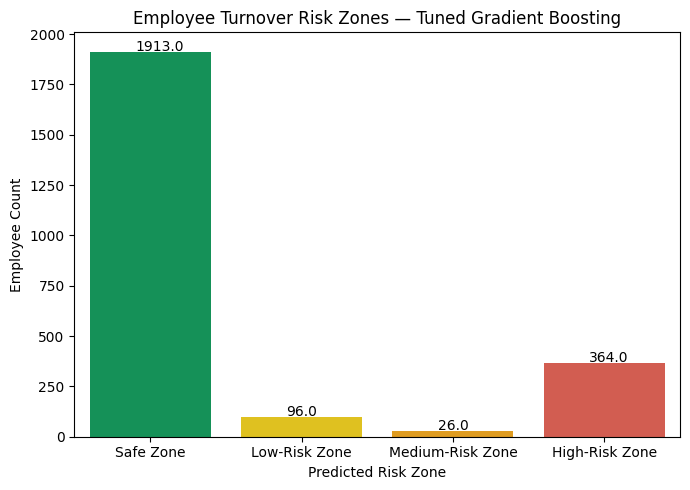

In [37]:
plt.figure(figsize=(7,5))
color_map = ['#00A65A', '#FFD700', '#FFA500', '#E74C3C']  # Green, Yellow, Orange, Red

ax = sns.countplot(
    x='Risk_Category',
    data=risk_df,
    order=labels,
    palette=color_map
    )

for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + 0.3, p.get_height() + 5))

plt.title('Employee Turnover Risk Zones — Tuned Gradient Boosting')
plt.xlabel('Predicted Risk Zone')
plt.ylabel('Employee Count')
plt.tight_layout()
plt.show()

#### *11.4 Examine Attrition by Risk Zone*

To assess whether the illustrative risk zones meaningfully separate employees with different observed turnover outcomes, we examine the actual attrition rate within each predicted risk category. Effective risk stratification should show progressively higher observed attrition rates across higher-risk zones.

In [38]:
tier_summary = (
    risk_df.groupby('Risk_Category')['Actual']
    .mean()
    .rename('Actual_Attrition_Rate')
    .reset_index()
)

tier_summary['Actual_Attrition_Rate'] = (tier_summary['Actual_Attrition_Rate'] * 100).round(1)
tier_summary

,Risk_Category,Actual_Attrition_Rate
0,Safe Zone,1.300
1,Low-Risk Zone,9.400
2,Medium-Risk Zone,38.500
3,High-Risk Zone,97.300


#### *11.5 Interpretation of Results*

The tuned Gradient Boosting model provides clear separation across the four illustrative risk zones:

- **Safe Zone (Green, <20%)** — 1.3% observed attrition rate in the test set.
- **Low-Risk Zone (Yellow, 20–60%)** — 9.4% observed attrition rate.
- **Medium-Risk Zone (Orange, 60–90%)** — 38.5% observed attrition rate.
- **High-Risk Zone (Red, ≥90%)** — 97.3% observed attrition rate.

Observed attrition rises progressively across the four risk zones, indicating that the model's predicted probabilities provide strong separation between lower- and higher-risk observations in the held-out test set.

These results demonstrate the potential usefulness of probability-based risk stratification for decision support, while the specific thresholds would require further validation before operational use.

#### *11.6 Probability Distribution Plot*
A kernel density plot visualizes the continuous distribution of predicted probabilities, color-coded by risk zone.

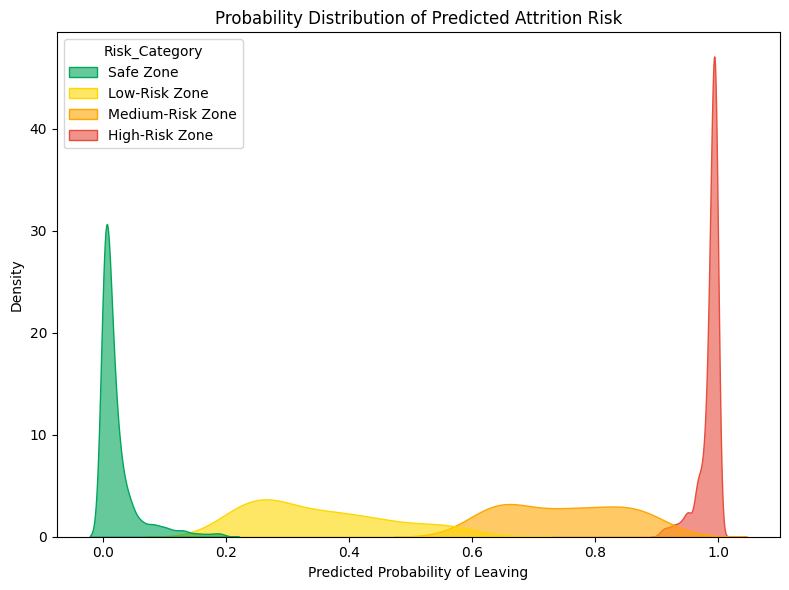

In [39]:
plt.figure(figsize=(8,6))

sns.kdeplot(
    data=risk_df, x='Predicted_Prob', hue='Risk_Category',
    fill=True, common_norm=False, palette=color_map, alpha=0.6
)

plt.title('Probability Distribution of Predicted Attrition Risk')
plt.xlabel('Predicted Probability of Leaving')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

### *Risk Stratification Summary*

Model probabilities were converted into four illustrative risk zones: **Safe (Green), Low-Risk (Yellow), Medium-Risk (Orange), and High-Risk (Red)**.

Observed outcomes in the held-out test set demonstrate strong separation across these categories, with attrition frequency increasing sharply from the Safe Zone to the High-Risk Zone.

In a potential decision-support setting, this type of risk framework could help HR teams identify groups for further review and prioritize retention analysis. The specific thresholds and any resulting interventions would require organizational validation before operational use.

The next section saves the final model and feature metadata to support reproducibility and demonstrate how the trained model could be preserved for future inference.

## 12. Save Artifacts (Model, Columns)

With the analysis complete and the tuned Gradient Boosting model selected according to the project's recall-focused criterion, the final step is to **save the key artifacts** for future reuse and evaluation.

Saving these artifacts supports reproducibility by allowing the trained model and its corresponding feature schema to be reloaded later without retraining, for either inference or further evaluation.

#### *12.1 Save Trained Model*

The tuned Gradient Boosting pipeline (including SMOTE and the classifier) is saved using `joblib` for efficient serialization.

In [40]:
# Create output directory if it doesn't exist
os.makedirs('artifacts', exist_ok=True)

# Save tuned Gradient Boosting model
joblib.dump(best_model, 'artifacts/final_gradient_boosting_model.joblib')

print("Model saved successfully as 'artifacts/final_gradient_boosting_model.joblib'")

Model saved successfully as 'artifacts/final_gradient_boosting_model.joblib'


#### *12.2 Save Column Names and Feature Metadata*
To maintain schema consistency, the column names used for model training are also saved. This ensures that any future input data conforms to the same structure and encoding.

In [41]:
# Save column list (feature schema)
feature_columns = X_train.columns.to_list()
joblib.dump(feature_columns, 'artifacts/model_feature_columns.joblib')

print("Feature column names saved as 'artifacts/model_feature_columns.joblib'")

print(f"Number of features saved: {len(feature_columns)}")

Feature column names saved as 'artifacts/model_feature_columns.joblib'
Number of features saved: 18


#### *12.3 Verify Reload Functionality*
To confirm successful artifact creation, we reload the saved model and run a quick verification check on structure and prediction capability.

In [42]:
# Reload model and columns
loaded_model = joblib.load('artifacts/final_gradient_boosting_model.joblib')
loaded_columns = joblib.load('artifacts/model_feature_columns.joblib')

# Test prediction on sample
sample = X_test.iloc[:5]
sample_predictions = loaded_model.predict(sample)

print("Model reloaded successfully and produced predictions:")
print(sample_predictions)

assert loaded_columns == list(X_test.columns), "Column mismatch after reload!"

Model reloaded successfully and produced predictions:
[0 0 0 1 0]


#### *12.4 Professional Practice Note*

In a production setting, these artifacts would typically be stored in a version-controlled directory or object store (e.g., AWS S3, Azure Blob, or a version-controlled repository). Maintaining consistent model versioning and input schemas is important for traceability, reproducibility, and model governance.

The artifacts created here support:

- Consistent inference without retraining.

- Future integration with dashboards or APIs.

- Reproducibility and subsequent model evaluation within the project lifecycle.

### *Artifact Preservation Summary*

- The tuned Gradient Boosting pipeline and corresponding feature schema were saved successfully using `joblib`.

- Verification confirmed that the saved artifacts can be reloaded successfully and that the model can generate predictions using the expected feature schema.

- This step completes the model-preservation component of the project and supports reproducibility and future evaluation.

- The final section will present the **Executive Summary** — synthesizing key findings, model insights, and potential applications for HR decision support.

## 13. Executive Summary — Findings & Recommendations

##### This project applied supervised machine learning to predict employee turnover using a historical HR dataset. The analysis progressed through all major stages of a data science workflow—from data validation and exploratory analysis to feature engineering, model training, tuning, evaluation, and risk stratification.

##### The following summary presents the key findings, model insights, and potential organizational applications based on the tuned Gradient Boosting model, which was selected according to the project's recall-focused evaluation criterion.

#### *13.1 Project Overview*

**Objective:**  
Develop a predictive model to identify employees at risk of leaving the company and demonstrate how model outputs could support proactive retention analysis.

**Approach:**  
- Conducted exploratory data analysis (EDA) to understand distributions, correlations, and attrition patterns.  
- Applied data preprocessing, encoding, and class rebalancing using SMOTE.  
- Built and evaluated baseline models (Logistic Regression, Random Forest, Gradient Boosting), then used cross-validation for hyperparameter tuning.  
- Evaluated models on recall, precision, F1-score, and ROC-AUC.  
- Translated model outputs into illustrative risk tiers (Safe, Low, Medium, High).  

**Selected Model:**  
- **Tuned Gradient Boosting Classifier**  
  - Achieved recall of **0.920**, precision of **0.910**, F1-score of **0.915**, and ROC-AUC of **0.980** on the held-out test set.  
  - Selected according to the project's recall-focused criterion, with slightly higher recall, F1, and ROC-AUC than the tuned Random Forest model.  
  - Provides feature importance values that support interpretation of the variables contributing most strongly to model predictions.

### *13.2 Key Findings*

1. **Predictive Performance**

   The tuned Gradient Boosting model achieved strong performance on the held-out test set, with recall of **0.920**, precision of **0.910**, F1-score of **0.915**, and ROC-AUC of **0.980**.

2. **Key Predictive Features**

   Feature-importance analysis identified the following variables as the strongest contributors to the selected model's predictions:

   - **Satisfaction Level** — Highest feature importance (0.433).
   - **Time Spent with Company** — Second-highest importance (0.344).
   - **Last Evaluation Score** — Additional predictive importance (0.090).
   - **Average Monthly Hours** — Additional predictive importance (0.072).
   - **Number of Projects** — Additional predictive importance (0.030).

   These feature-importance values identify the variables on which the model relies most heavily, but do not by themselves establish the direction of each relationship or demonstrate that these features cause employee turnover.

3. **Risk Stratification**

   - The four illustrative risk zones (Safe, Low, Medium, High) show strong separation in the held-out test set, with observed attrition rates increasing progressively across the categories.
   - Observed attrition rates were **1.3%** in the Safe Zone, **9.4%** in the Low-Risk Zone, **38.5%** in the Medium-Risk Zone, and **97.3%** in the High-Risk Zone.
   - These results demonstrate strong risk separation within the test data, while the specific probability thresholds would require further validation before operational use.

### *13.3 Potential Applications for HR Leadership*

1. **Use Risk Scores to Support Further Review**

   - The model's risk categories could help identify groups for additional analysis or voluntary retention efforts.
   - Model outputs should supplement, rather than replace, human judgment and should not be used as the sole basis for employment decisions.

2. **Monitor Key Predictive Indicators**

   - Satisfaction level, tenure, number of projects, evaluation scores, and average monthly hours were the model's most influential predictive features.
   - HR teams could examine these indicators alongside employee feedback and organizational context to better understand patterns associated with turnover.

3. **Investigate Underlying Organizational Factors**

   - Predictive patterns can identify areas for further investigation, but additional analysis would be needed to determine why particular employee groups leave.
   - Potential factors such as workload, compensation, management practices, or career development should be evaluated directly before designing interventions.

4. **Validate Before Operational Use**

   - Before integration into HR workflows, the model should be evaluated on current organizational data and the illustrative risk thresholds should be validated for the intended use.
   - Ongoing monitoring would be needed to assess model performance, data drift, and changes in workforce patterns over time.

5. **Maintain Human Oversight and Responsible Use**

   - Predictive turnover analysis is best suited to supporting retention planning rather than making automated employment decisions.
   - Any operational use should include appropriate review for fairness, privacy, transparency, and unintended consequences.

### *13.4 Limitations and Ethical Considerations*

1. **Data Scope**

   The dataset reflects historical HR conditions and may not capture current cultural, organizational, or economic factors affecting employee turnover.

2. **Model Generalization**

   - Performance on this dataset does not establish that the model will generalize to other organizations or workforce populations.
   - Any application to a new organizational setting would require validation using relevant local data and may require retraining.

3. **Potential Bias**

   - Predictive models may inadvertently reflect existing organizational biases.
   - Any operational use should include appropriate fairness evaluation and ongoing monitoring for disparate or unintended effects.

4. **Ethical Use**

   - Predictive results should **never** be used punitively or as the sole basis for employment decisions.
   - Instead, turnover predictions could support voluntary, employee-centered retention efforts and further organizational analysis.

5. **Privacy and Governance**

   - Employee data should be handled according to appropriate privacy, access-control, and data-governance requirements.
   - Model access, use, and performance should be documented and monitored throughout the model lifecycle.

## Final Reflection

### The tuned Gradient Boosting model achieved strong predictive performance on the held-out test set, with recall of 0.920, precision of 0.910, F1-score of 0.915, and ROC-AUC of 0.980.

### Satisfaction level, time spent with the company, number of projects, last evaluation, and average monthly hours emerged as the model's most influential predictive features. Together, the results demonstrate how machine learning can be used to identify patterns associated with employee turnover and support further analysis and responsible decision-making.